# Parametric insurance in ten minutes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/marc272/crc-docs/blob/parametric/notebooks/parametric_insurance_primer.ipynb)

A normal insurance policy pays **what you lost**, after someone has come to look.
A **parametric** policy pays **what a measured number says**: if the rain on one
day passes an agreed level, an agreed amount is paid. No adjuster, no claim form,
no argument about the size of the loss.

Two public schemes show the idea at national scale:

- **CCRIF SPC** describes itself as the
  [world's first multi-country, multi-peril risk pool based on parametric insurance](https://www.ccrif.org/about-us?language_content_entity=en).
  Its 40 members are mostly Caribbean and Central American governments and
  utilities, and by its own count it made 83 payouts totalling about US$500 million
  between June 2007 and October 2026. One of them went to
  [Panama: US$26.7 million after the excess rainfall of 31 October to 4 November 2024](https://www.ccrif.org/news/government-panama-receives-us267-million-following-excess-rainfall-event?language_content_entity=en).
- **African Risk Capacity (ARC)** insures African governments against drought. A
  member [receives a payout when rainfall deviates enough](https://www.arc.int/how-arc-works)
  that the response costs estimated by its model, Africa RiskView, cross a
  threshold agreed in advance, and ARC says the money arrives two to four weeks
  after the rainy season ends. Its
  [risk-pool record](https://www.arc.int/risk-pools) lists US$206.1 million of
  payouts, 13 risk pools and 20 member states covered.

Speed is the selling point. The catch is that the payout follows the number, not
your loss. This primer shows what that means, one chart per idea, with the
parametric module of the open toolkit [crc-sdk](https://github.com/RiskThinking/crc-sdk).

**The one thing to take away: a cover is a function you can design, and test
honestly, including when it fails to pay.**

You should know what a hazard curve is
([five-minute primer](climate_risk_curves_primer.ipynb) if not), but nothing about
insurance. On Colab choose **Runtime → Run all**; no account needed. The first run
installs crc-sdk and downloads one small CRC Open file, in a minute or two. On GitHub
the sliders and buttons show as saved images.

## Setup

In [1]:
#@title Install packages (Colab)
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None

# crc_sdk.parametric is not in a crc-sdk release yet: install it from its development branch.
CRC_SDK = "crc-sdk[geometry,parametric] @ git+https://github.com/marc272/crc-sdk@parametric"


def has_parametric():
    spec = importlib.util.find_spec("crc_sdk")
    return spec is not None and spec.origin is not None and (Path(spec.origin).parent / "parametric").is_dir()


def pip_install(*arguments):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments])


if IN_COLAB or not has_parametric():
    if importlib.util.find_spec("pip") is None:  # a bare virtual environment
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(CRC_SDK, "plotly>=6,<7", "pandas>=2.2")
    if not has_parametric():  # a crc-sdk release of the same version number was already installed
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    importlib.invalidate_caches()

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"

In [2]:
import warnings

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
from IPython.display import display
from plotly.subplots import make_subplots

from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    CostOfCapitalLoad, Cover, HazardNoise, IndexDefinition, LinearPayout, LossModel, PurePremium, compare, evaluate,
    sample_curve,
)
from crc_sdk.workflows import HazardDataset, distribution_from_hazard_row
from crc_sdk.workflows.distributions import ReturnPeriodExtrapolationWarning

# About 1 simulated year in 1,000 falls outside the return periods the curve was fitted on
# (1.001 to 1,000 years), where it is extrapolated. We accept that and silence the warning.
warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000

DATA = Path("data") / "parametric_primer"
DATA.mkdir(parents=True, exist_ok=True)

# Orange is always the loss and blue the payout.
INK, BLUE, ORANGE, MUTED, LIGHT = "#52514e", "#2a78d6", "#eb6834", "#8a8880", "#f0efec"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, setup, height=500, bottom=70, top=120, **kwargs):
    """Style a chart and state its setup under the title, so the numbers never lose it."""
    fig.update_layout(title=dict(text=title, x=0.01, y=0.97, yanchor="top",
                                 subtitle=dict(text=setup, font=dict(size=11, color=MUTED))),
                      font=FONT, height=height, margin=dict(l=75, r=30, t=top, b=bottom), hoverlabel=dict(font_size=13), **kwargs)
    return fig


def cad(value):
    return f"CAD {value:,.0f}"

## The example: a brewery with a wet basement

Imagine **Wet Basement Brewing**, a craft brewery in Toronto with its tanks and
cold room below street level. It is made up: the name, its value of CAD 5 million
and the way it floods are illustrations, not a real business or a real contract.

Three ingredients go in:

1. **The rain.** CRC Open's `rx1day`, the rain on the wettest day of the year, for
   the hexagon around the site (about 250 km²), under SSP5-8.5, the one future the
   public release covers, in 2030 (a cover is written for the near term). CRC Open
   has no historical baseline, so everything simulated below describes that
   future, not the past.
2. **The damage.** A hypothetical curve: nothing up to 40 mm in a day, then the
   drains give up and the damage climbs.
3. **The gap between the rain and the loss**, which section 3 explains.

In [3]:
RELEASE, PATHWAY, HORIZON = "ssp585-global-2026-10-20-v1", "ssp585", 2030
ASSET = {"asset_id": "Wet Basement Brewing", "longitude": -79.38, "latitude": 43.65, "value_cad": 5_000_000.0}

# Downloads and checks the CRC Open file once, then reads the cached copy.
dataset = (
    HazardDataset.crc_open(release=RELEASE)
    .hazards(["rx1day"])
    .horizons([HORIZON])
    .for_area((-79.40, 43.63, -79.36, 43.67))  # (west, south, east, north), enough to find the site's hexagon
    .cache(DATA / "crc-open", mode="reuse")
    .ensure_materialized()
)
metadata = dataset.metadata()
curve_row = (
    dataset.for_assets(pa.Table.from_pylist([ASSET]))
    .select(hazard_names=["rx1day"], horizons=[HORIZON], pathways=[PATHWAY])
    .asset_curves()
    .to_pylist()[0]
)
curve = distribution_from_hazard_row(curve_row)

DAMAGE = ImpactExpression.tabulated(
    [(40.0, 0.0), (50.0, 0.02), (60.0, 0.06), (75.0, 0.15), (100.0, 0.30)],
    calibration=ImpactCalibration(exposure_variable="rx1day", exposure_unit="mm/day",
                                  impact_metric="damage_ratio", impact_unit="1"),
    clamp={"minimum": 0.0, "maximum": 1.0},
)

frequent, rare = metadata.source_probability_support
print(f"CRC Open rx1day ({metadata.value_unit}), release {RELEASE}, pathway {PATHWAY}, horizon {HORIZON}, "
      f"hexagon {curve_row['cell_index']:x}; {metadata.ensemble.pooling} over an ensemble of climate models.")
print(f"Declared meaning: {metadata.probability_semantics}, so one draw from the curve is one year. "
      f"Fitted between return periods {1 / (1 - frequent):.3f} and {1 / (1 - rare):,.0f} years.")
print(f"Licence: {metadata.source.licence}. Attribution: {metadata.source.attribution}.")

CRC Open rx1day (mm/day), release ssp585-global-2026-10-20-v1, pathway ssp585, horizon 2030, hexagon 852b9bc7fffffff; pooled over an ensemble of climate models.
Declared meaning: annual_value_distribution, so one draw from the curve is one year. Fitted between return periods 1.001 and 1,000 years.
Licence: CC-BY-NC-4.0. Attribution: Riskthinking.AI bias-corrected climate distributions.


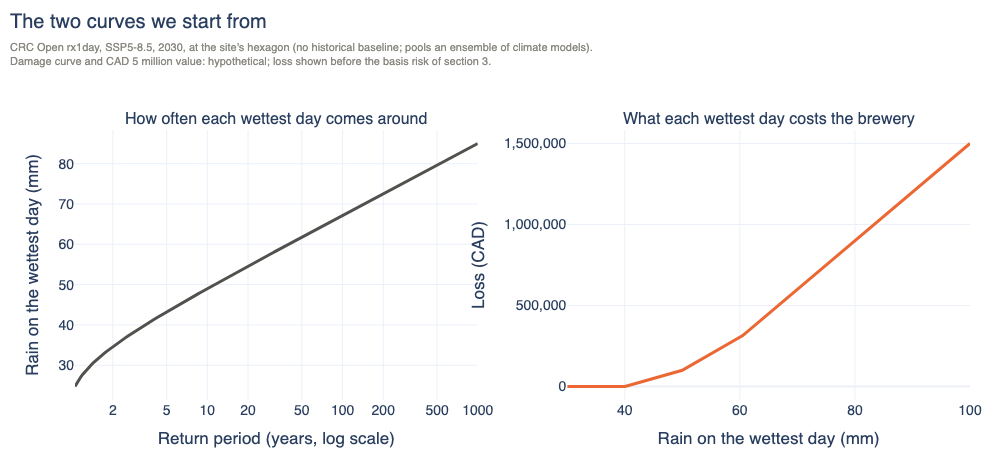

In [4]:
periods = np.geomspace(1.05, 1_000, 200)
rain = np.asarray(curve.quantiles(1 - 1 / periods), dtype=float)
rain_grid = np.linspace(30.0, 100.0, 141)
loss_grid = ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(rain_grid), dtype=float)

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1,
                    subplot_titles=("How often each wettest day comes around", "What each wettest day costs the brewery"))
fig.add_trace(go.Scatter(x=periods, y=rain, mode="lines", line=dict(color=INK, width=3), showlegend=False,
                         hovertemplate="1-in-%{x:.0f} years: %{y:.0f} mm<extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(x=rain_grid, y=loss_grid, mode="lines", line=dict(color=ORANGE, width=3), showlegend=False,
                         hovertemplate="%{x:.0f} mm: loss CAD %{y:,.0f}<extra></extra>"), row=1, col=2)
fig.update_xaxes(type="log", tickvals=[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000], title_text="Return period (years, log scale)", row=1, col=1)
fig.update_yaxes(title_text="Rain on the wettest day (mm)", row=1, col=1)
fig.update_xaxes(title_text="Rain on the wettest day (mm)", row=1, col=2)
fig.update_yaxes(title_text="Loss (CAD)", tickformat=",.0f", row=1, col=2)
layout(fig, "The two curves we start from",
       f"CRC Open rx1day, SSP5-8.5, {HORIZON}, at the site's hexagon (no historical baseline; pools an ensemble of climate models).<br>"
       f"Damage curve and CAD 5 million value: hypothetical; loss shown before the basis risk of section 3.", height=470, top=130)
fig.show()

Now the simulated years. `sample_curve` rolls the curve once per year and gives
the rain (the **index** the cover pays on) and the loss. We draw two separate sets,
**design years** for choosing terms and **fresh years** for testing them; every
number below is on the fresh years.

In [5]:
SIGMA = 0.25
N_YEARS = 2_000 if CI else 20_000
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")
basis_risk = HazardNoise(SIGMA)  # section 3


def simulate(seed):
    return sample_curve(curve_row, metadata=metadata, n_draws=N_YEARS, rng=np.random.default_rng(seed),
                        loss_model=loss_model, basis_risk=basis_risk, asset_id=ASSET["asset_id"])


design_years, fresh_years = simulate(seed=42), simulate(seed=7)
rain_years = fresh_years.index[:, 0]  # the index: rain on the hexagon, one value per fresh year
loss_years = fresh_years.loss[:, 0]   # the loss, in CAD
print(f"{N_YEARS:,} design years and {N_YEARS:,} fresh years. Fresh years: "
      f"mean loss {cad(loss_years.mean())} a year, a loss in {(loss_years > 0).mean():.0%} of years.")

SETUP = (f"Setup: one imaginary asset · annual basis, one draw = one year · basis risk: HazardNoise, σ = {SIGMA} · "
         f"CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline) ·<br>hypothetical damage and value · "
         f"out of sample: {N_YEARS:,} fresh simulated years")

20,000 design years and 20,000 fresh years. Fresh years: mean loss CAD 59,659 a year, a loss in 31% of years.


## 1. A cover is a function

A parametric cover is a **function**: rain in, money out. Here is a simple one
for the brewery. Pay nothing below 45 mm in a day (the **attachment**), pay the
full CAD 500,000 from 75 mm (the **exhaustion**), and rise in a straight line
between the two. That is one line of code:

In [6]:
index = IndexDefinition("rx1day", "mm/day", aggregation="annual_maximum")
first_cover = Cover(index, LinearPayout(45.0, 75.0, 500_000.0), payout_unit="CAD", label="First cover")

first_cover.payout_values([30.0, 45.0, 60.0, 90.0])  # rain in, CAD out

array([     0.,      0., 250000., 500000.])

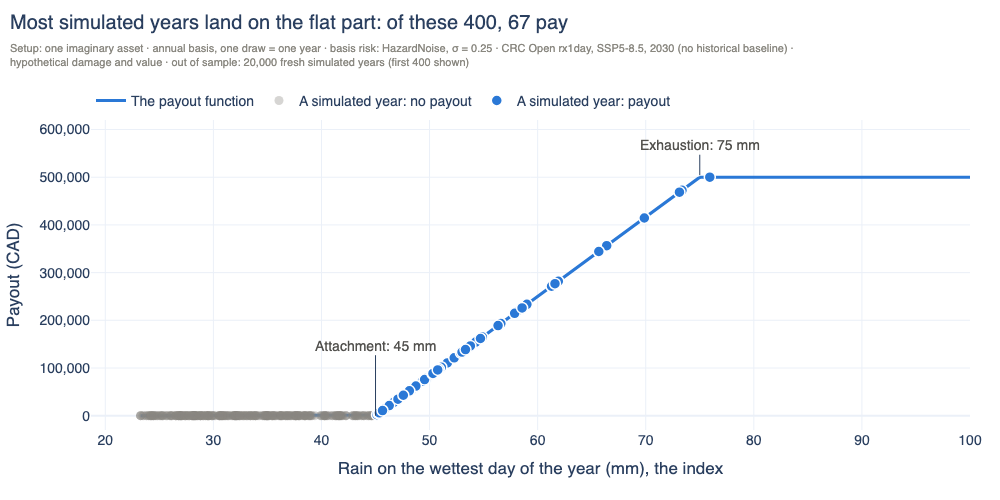

In [7]:
paid = first_cover.payout_values(rain_years)
shown = np.arange(min(400, N_YEARS))
pays = paid[shown] > 0
grid = np.linspace(rain_years[shown].min(), max(100.0, rain_years[shown].max()), 300)

fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=first_cover.payout_values(grid), mode="lines", line=dict(color=BLUE, width=3),
                         name="The payout function", hovertemplate="%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
fig.add_trace(go.Scatter(x=rain_years[shown][~pays], y=paid[shown][~pays], mode="markers", name="A simulated year: no payout",
                         marker=dict(size=9, color=MUTED, opacity=0.35, line=dict(width=0)),
                         hovertemplate="Rain %{x:.0f} mm: no payout<extra></extra>"))
fig.add_trace(go.Scatter(x=rain_years[shown][pays], y=paid[shown][pays], mode="markers", name="A simulated year: payout",
                         marker=dict(size=11, color=BLUE, line=dict(width=1.5, color="white")),
                         hovertemplate="Rain %{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
fig.add_annotation(x=45, y=0, text="Attachment: 45 mm", showarrow=True, arrowhead=0, ax=0, ay=-70, font=dict(color=INK))
fig.add_annotation(x=75, y=500_000, text="Exhaustion: 75 mm", showarrow=True, arrowhead=0, ax=0, ay=-30, font=dict(color=INK), yshift=2)
layout(fig, f"Most simulated years land on the flat part: of these {len(shown)}, {int(pays.sum())} pay",
       SETUP + f" (first {len(shown)} shown)",
       xaxis_title="Rain on the wettest day of the year (mm), the index", yaxis=dict(title="Payout (CAD)", tickformat=",.0f", range=[-30_000, 620_000]),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0))
fig.show()

> 💡 **Key idea: the contract is a function.** A cover is an **index**, a
> **payout function** and a currency. Here
> `payout = 500,000 × clip((rain − 45) / (75 − 45), 0, 1)`. The module also ships
> step, piecewise-linear and all-or-nothing payouts, and takes your own. The terms
> are just data, so a cover can be saved, hashed and compared exactly
> (`first_cover.to_json()`, `first_cover.definition_hash`).

## 2. How often does it pay?

The brewery pays its premium every year. The payout comes only sometimes. Here
are 100 simulated years, with the loss and the payout of each. Drag the slider to
roll another 100.

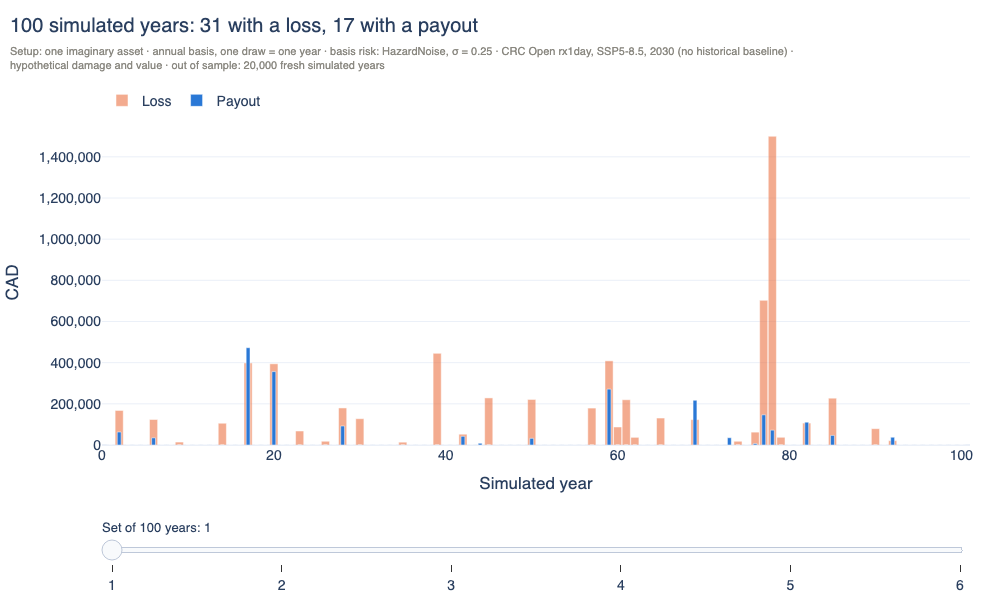

Across all 20,000 fresh years: the cover pays in 16.5% of years (about 1 in 6), and the brewery has a loss in 31.5% of years.


In [8]:
first_row = evaluate(first_cover, fresh_years, split="out_of_sample", design_sample=design_years).to_pylist()[0]

CENTURIES = 3 if CI else 6
years_axis = np.arange(1, 101)
fig = go.Figure()
for century in range(CENTURIES):
    start, stop = century * 100, (century + 1) * 100
    fig.add_trace(go.Bar(x=years_axis, y=loss_years[start:stop], name="Loss", marker_color=ORANGE, opacity=0.55,
                         visible=century == 0, width=0.95, hovertemplate="Year %{x}: loss CAD %{y:,.0f}<extra></extra>"))
    fig.add_trace(go.Bar(x=years_axis, y=paid[start:stop], name="Payout", marker_color=BLUE,
                         visible=century == 0, width=0.45, hovertemplate="Year %{x}: payout CAD %{y:,.0f}<extra></extra>"))


def century_title(century):
    start, stop = century * 100, (century + 1) * 100
    return (f"100 simulated years: {(loss_years[start:stop] > 0).sum()} with a loss, "
            f"{(paid[start:stop] > 0).sum()} with a payout")


steps = [dict(method="update", label=str(century + 1),
              args=[{"visible": [trace // 2 == century for trace in range(2 * CENTURIES)]},
                    {"title.text": century_title(century)}])
         for century in range(CENTURIES)]
layout(fig, century_title(0), SETUP, barmode="overlay", bargap=0.2,
       xaxis=dict(title="Simulated year", range=[0, 101]), yaxis=dict(title="CAD", tickformat=",.0f", rangemode="tozero"),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=600, bottom=130,
       sliders=[dict(active=0, currentvalue=dict(prefix="Set of 100 years: ", font=dict(size=13)), pad=dict(t=70), steps=steps)])
fig.show()

print(f"Across all {N_YEARS:,} fresh years: the cover pays in {first_row['payout_frequency']:.1%} of years "
      f"(about 1 in {1 / first_row['payout_frequency']:.0f}), and the brewery has a loss in {(loss_years > 0).mean():.1%} of years.")

> 💡 **Key idea: most years, nothing happens.** A cover is a claim on rare years.
> That is why a return-period curve, which you already know how to read, is the
> right tool for pricing and testing it. It also means the honest test needs a lot
> of years: 30 years of history would contain only a handful of payouts.

## 3. Basis risk: when the rain and the loss disagree

The payout follows the rain on the hexagon; the loss follows the water in the
basement. A 250 km² hexagon can be soaked by a storm that misses the brewery, or
stay dry on average while a storm sits right on top of it. `HazardNoise(0.25)`
above models that: each year, the rain at the brewery is the rain on the hexagon
times a random factor with mean 1. Its σ = 0.25 is an assumption of this
illustration, not an estimate.

The gap is called **basis risk**, and it fails in two opposite ways: a loss with
no payout, and a payout with no loss.

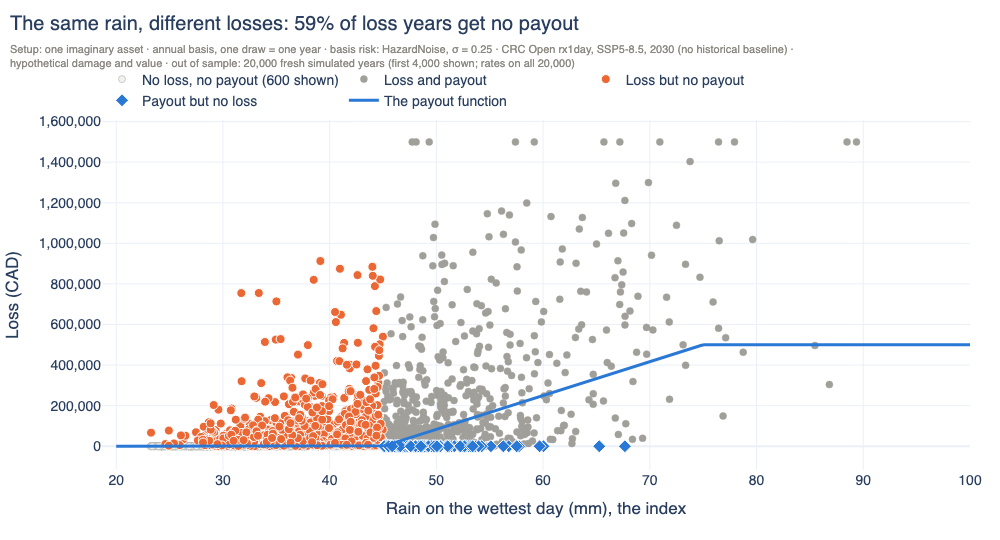

On the fresh years: 59.0% of the years with a loss get no payout, and 5.3% of the years without a loss get one. Payouts and losses have a correlation of 0.61.


In [9]:
n_shown = min(4_000, N_YEARS)
x, y, payout = rain_years[:n_shown], loss_years[:n_shown], paid[:n_shown]
missed = (y > 0) & (payout == 0)       # a loss, but no payout
false_alarm = (y == 0) & (payout > 0)  # a payout, but no loss
quiet = (y == 0) & (payout == 0)
other = ~(missed | false_alarm | quiet)

fig = go.Figure()
keep_quiet = np.flatnonzero(quiet)[:600]  # the many quiet years would hide the rest
for mask, name, color in [(keep_quiet, "No loss, no payout (600 shown)", LIGHT), (other, "Loss and payout", MUTED)]:
    fig.add_trace(go.Scatter(x=x[mask], y=y[mask], mode="markers", name=name, opacity=0.8,
                             marker=dict(size=7, color=color, line=dict(width=0.5, color=MUTED)), hoverinfo="skip"))
fig.add_trace(go.Scatter(x=x[missed], y=y[missed], mode="markers", name="Loss but no payout",
                         marker=dict(size=9, color=ORANGE, line=dict(width=1, color="white")),
                         hovertemplate="Rain on the hexagon %{x:.0f} mm<br>Loss CAD %{y:,.0f}, payout CAD 0<extra></extra>"))
fig.add_trace(go.Scatter(x=x[false_alarm], y=y[false_alarm], mode="markers", name="Payout but no loss",
                         marker=dict(size=10, color=BLUE, symbol="diamond", line=dict(width=1, color="white")),
                         hovertemplate="Rain on the hexagon %{x:.0f} mm<br>No loss, payout CAD %{customdata:,.0f}<extra></extra>",
                         customdata=payout[false_alarm]))
grid = np.linspace(20.0, 100.0, 300)
fig.add_trace(go.Scatter(x=grid, y=first_cover.payout_values(grid), mode="lines", name="The payout function",
                         line=dict(color=BLUE, width=3), hoverinfo="skip"))
layout(fig, f"The same rain, different losses: {first_row['false_negative_rate_l0']:.0%} of loss years get no payout",
       SETUP + f" (first {n_shown:,} shown; rates on all {N_YEARS:,})",
       xaxis_title="Rain on the wettest day (mm), the index", yaxis=dict(title="Loss (CAD)", tickformat=",.0f"),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=540)
fig.show()

print(f"On the fresh years: {first_row['false_negative_rate_l0']:.1%} of the years with a loss get no payout, and "
      f"{first_row['false_positive_rate_l0']:.1%} of the years without a loss get one. "
      f"Payouts and losses have a correlation of {first_row['correlation']:.2f}.")

Orange marks the first way: the hexagon stayed below the attachment, but the
brewery had a loss. Blue marks the second: the hexagon reached the attachment, but
the storm missed the brewery. The module reports both rates for any cover
(`false_negative_rate_l0`, `false_positive_rate_l0`).

> 💡 **Key idea: basis risk is the price of a fast payout, and it is real.** In
> Malawi's 2015/16 drought, ARC's [policy did not trigger at first](https://www.arc.int/index.php/news/press-release-malawi-receive-usd-8m-insurance-payout-support-drought-affected-families)
> because the model showed few people affected. ARC's review found the model had
> worked as specified, but farmers had moved to a 90-day maize while the model
> assumed a 120–140-day one. ARC amended the policy and agreed a payout of about
> US$8.1 million. [ActionAid's review](https://actionaid.org/publications/2017/wrong-model-resilience)
> called the payment too little and too late. The model did what it was specified
> to do, and still missed the loss.

## 4. What it costs

The break-even price is the **pure premium**: what the cover pays out on average.
A real insurer also holds capital for its worst year and charges for that, so a
real premium is higher. Both are one argument away:

In [10]:
PRICES = {"Pure premium: the expected payout": PurePremium(),
          "With a 6% cost of capital held against the 1-in-100 tail": CostOfCapitalLoad(0.06, 0.99)}
cost = pd.DataFrame({
    label: evaluate(first_cover, fresh_years, split="out_of_sample", design_sample=design_years, pricing=pricing).to_pylist()[0]
    for label, pricing in PRICES.items()
}).T[["premium", "expected_payout", "expected_loss"]].astype(float)
cost["premium / expected loss"] = cost["premium"] / cost["expected_loss"]
display(cost.style.format({"premium": "{:,.0f}", "expected_payout": "{:,.0f}", "expected_loss": "{:,.0f}",
                           "premium / expected loss": "{:.0%}"}))
print(f"CAD per year. One imaginary asset, annual basis, HazardNoise σ = {SIGMA}, out of sample on {N_YEARS:,} fresh "
      f"simulated years from CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline). "
      f"The cost-of-capital rate and level are illustrative, not a market quote.")

,premium,expected_payout,expected_loss,premium / expected loss
Pure premium: the expected payout,"21,214","21,214","59,659",36%
With a 6% cost of capital held against the 1-in-100 tail,"46,778","21,214","59,659",78%


CAD per year. One imaginary asset, annual basis, HazardNoise σ = 0.25, out of sample on 20,000 fresh simulated years from CRC Open rx1day, SSP5-8.5, 2030 (no historical baseline). The cost-of-capital rate and level are illustrative, not a market quote.


> 💡 **Key idea: the premium is a statement about the curve.** The pure premium is
> `E[payout]`: the payout function averaged over the rain curve, so it moves as the
> hazard moves. The loaded premium here is
> `P = (1 − rate) · E[payout] + rate · CVaR_q(payout)`, the module's
> `CostOfCapitalLoad(rate, q)`. A warmer or wetter curve changes the price without
> anyone touching the contract.

## 5. Which rain?

Everything here pays on CRC Open's rain for the brewery's hexagon; a real contract
might pay on a weather station or a coarse grid cell instead, and that choice is
part of the design. A showcase on it, following this cover through Toronto's real
record of wettest days, the July 2013 storm included, is coming.

## 6. Build your own

Your turn. Pick where the cover starts paying with the slider, and the most it
pays with the buttons. Each combination was computed in advance with the module
on the same fresh years, so the controls work without a running kernel.

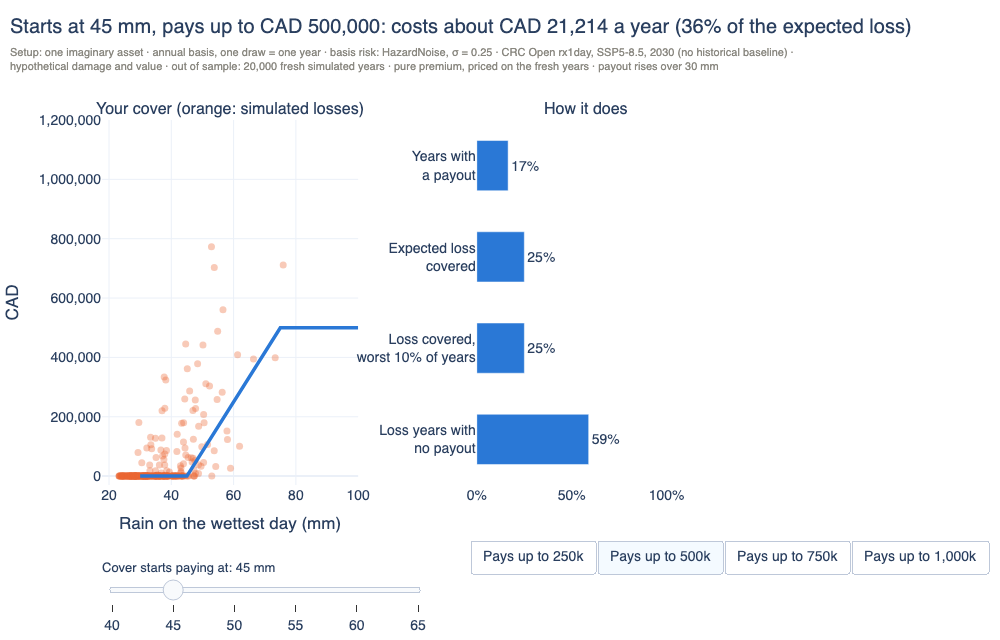

In [11]:
ATTACHMENTS = (40.0, 45.0, 50.0, 55.0, 60.0, 65.0)
MAXIMA = (250_000.0, 500_000.0, 750_000.0, 1_000_000.0)
GAP = 30.0  # the payout reaches its maximum 30 mm after it starts

covers = {(attachment, maximum): Cover(index, LinearPayout(attachment, attachment + GAP, maximum), payout_unit="CAD",
                                       label=f"{attachment:.0f} mm, up to {maximum:,.0f}")
          for maximum in MAXIMA for attachment in ATTACHMENTS}
results = compare(list(covers.values()), fresh_years, split="out_of_sample",
                  design_sample=design_years).to_pandas().set_index("cover_label")

METRICS = {"Years with<br>a payout": "payout_frequency", "Expected loss<br>covered": "coverage_ratio",
           "Loss covered,<br>worst 10% of years": "tail_coverage_b0_9", "Loss years with<br>no payout": "false_negative_rate_l0"}
fig = make_subplots(rows=1, cols=2, column_widths=[0.54, 0.46], horizontal_spacing=0.2,
                    subplot_titles=("Your cover (orange: simulated losses)", "How it does"))
fig.add_trace(go.Scatter(x=rain_years[:300], y=loss_years[:300], mode="markers", name="Simulated years: the loss",
                         marker=dict(size=7, color=ORANGE, opacity=0.35), hoverinfo="skip"), row=1, col=1)
first_trace = {}
plot_rain = np.linspace(30.0, 100.0, 141)
for key, cover in covers.items():
    values = results.loc[cover.label, list(METRICS.values())].astype(float).to_list()
    first_trace[key] = len(fig.data)
    fig.add_trace(go.Scatter(x=plot_rain, y=cover.payout_values(plot_rain), mode="lines", line=dict(color=BLUE, width=3.5),
                             visible=False, hovertemplate="%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Bar(x=values, y=list(METRICS), orientation="h", marker_color=BLUE, visible=False, width=0.55,
                         text=[f"{value:.0%}" for value in values], textposition="outside", cliponaxis=False,
                         hovertemplate="%{y}: %{x:.1%}<extra></extra>"), row=1, col=2)


def visible(attachment, maximum):
    first = first_trace[attachment, maximum]
    return [True] + [first <= trace <= first + 1 for trace in range(1, len(fig.data))]


def cover_title(attachment, maximum):
    row = results.loc[covers[attachment, maximum].label]
    return (f"Starts at {attachment:.0f} mm, pays up to {cad(maximum)}: "
            f"costs about {cad(row['premium'])} a year ({row['premium'] / row['expected_loss']:.0%} of the expected loss)")


def slider(maximum):
    return dict(active=1, currentvalue=dict(prefix="Cover starts paying at: ", suffix=" mm", font=dict(size=13)), pad=dict(t=70), len=0.55,
                steps=[dict(method="update", label=f"{attachment:.0f}",
                            args=[{"visible": visible(attachment, maximum)}, {"title.text": cover_title(attachment, maximum)}])
                       for attachment in ATTACHMENTS])


START = (ATTACHMENTS[1], MAXIMA[1])
for trace, shown in enumerate(visible(*START)):
    fig.data[trace].visible = shown
buttons = [dict(method="update", label=f"Pays up to {maximum / 1000:,.0f}k",
                args=[{"visible": visible(START[0], maximum)}, {"sliders": [slider(maximum)], "title.text": cover_title(START[0], maximum)}])
           for maximum in MAXIMA]
layout(fig, cover_title(*START),
       SETUP + f" · pure premium, priced on the fresh years · payout rises over {GAP:.0f} mm",
       height=640, bottom=140, showlegend=False, sliders=[slider(START[1])],
       updatemenus=[dict(type="buttons", direction="right", x=0.62, y=-0.15, xanchor="left", yanchor="top", showactive=True, active=1, buttons=buttons)])
fig.update_xaxes(title_text="Rain on the wettest day (mm)", row=1, col=1)
fig.update_yaxes(title_text="CAD", tickformat=",.0f", range=[-30_000, 1_200_000], row=1, col=1)
fig.update_xaxes(tickformat=".0%", range=[0, 1.15], row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.show()

> 💡 **Key idea: every term moves something you care about.** A cover that starts
> paying earlier pays more often and misses fewer loss years, but costs more. A
> higher maximum buys protection in the rare years. The right choice depends on
> what the brewery can absorb: the charts can inform it, not make it.

## Where next

The next notebook, on how the module works, picks up here: the module chooses a
cover's terms for a stated goal and budget, tests them on years they never saw, and
runs it all as one documented plan. It is coming; until then:

- Change the rain, the damage curve or the cover above and rerun.
- Try a step payout (`StepPayout`) or an all-or-nothing one (`BinaryPayout`).
- Read the module's [full guide](https://github.com/marc272/crc-sdk/blob/parametric/docs/parametric.md), and
  [How hard will it rain?](how_hard_will_it_rain.ipynb) for what the data says on
  its own.

*An ordinary loss-based policy and a parametric cover answer different questions:
one pays for what happened to you, the other for what happened to the measurement.
This notebook is an illustration of a method, not insurance advice or a price.*

*The tail-risk design ideas in this module come from Marc Prinzing's thesis,
"Tail-Risk Optimized Payout Design in Parametric Insurance".*

*Data: CRC Open by Riskthinking.AI (CC BY-NC 4.0; SSP5-8.5 only, no historical
baseline). The scheme facts in the introduction are from the linked publications.*